Dataset loaded successfully!
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
Index(['review', 'sentiment'], dtype='object')
Text column: review
Label column: sentiment

Preprocessed Reviews:
0    [reviewers, mentioned, watching, just, oz, epi...
1    [wonderful, little, production, filming, techn...
2    [thought, wonderful, way, spend, time, hot, su...
3    [basically, s, family, little, boy, jake, thin...
4    [petter, mattei, s, love, time, money, visuall...
Name: tokens, dtype: object

Label Distribution:
sentiment
1    25000
0    25000
Name: count, dtype: int64

Training samples: 40000
Testing samples: 10000

CBOW Model Training Completed!

Word: s
Embeddin

C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │          12,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 2)                   │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 21,314 (83.26 KB)

 Trainable params: 21,314 (83.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8388 - loss: 0.3653 - val_accuracy: 0.8602 - val_loss: 0.3204
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.8616 - loss: 0.3275 - val_accuracy: 0.8645 - val_loss: 0.3119
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - accuracy: 0.8662 - loss: 0.3182 - val_accuracy: 0.8634 - val_loss: 0.3180
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8688 - loss: 0.3139 - val_accuracy: 0.8679 - val_loss: 0.3067
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8712 - loss: 0.3086 - val_accuracy: 0.8656 - val_loss: 0.3074
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8726 - loss: 0.3055 - val_accuracy: 0.8622 - val_loss: 0.3160
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8748 - loss: 0.3007 - val_accuracy: 0.8661 - val_loss: 0.3093
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8754 - loss: 0.2979 - val_accuracy:

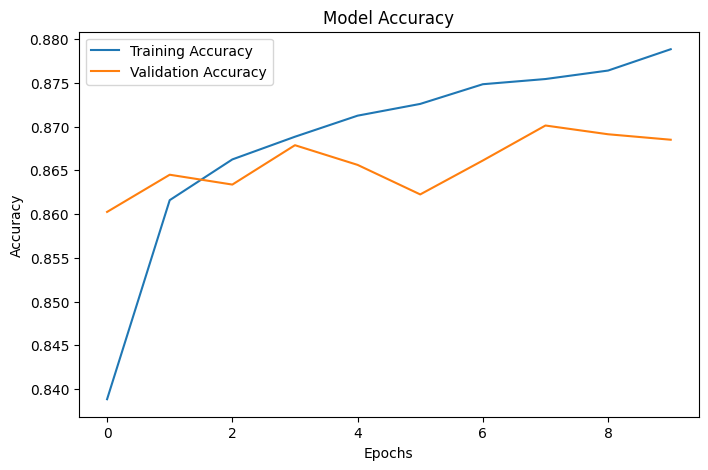

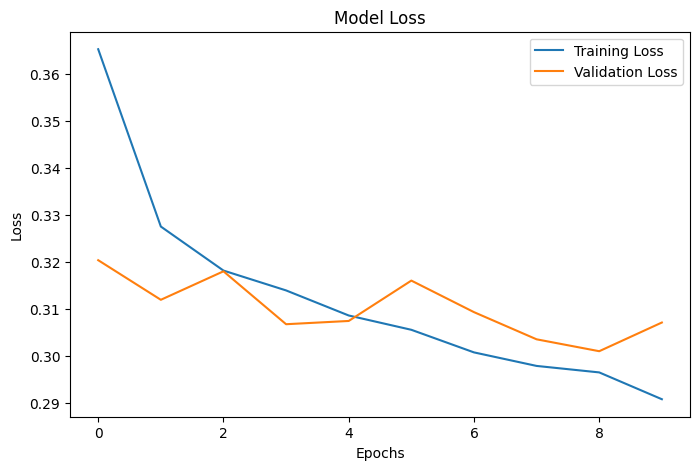


Enter a movie review:  good


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 432ms/step
Positive Review


In [1]:

# STEP 1: Import Libraries

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical


# STEP 2: Load IMDb Dataset

file_path = r"F:\lp4\LP IV Updated Datasets\CBOW\IMDB Dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(df.head())
print(df.columns)


# STEP 3: Identify Text and Label Columns

# Automatically detect common column names

text_column = next(
    (col for col in df.columns
     if col.lower() in ['review', 'text', 'sentence']),
    None
)

label_column = next(
    (col for col in df.columns
     if col.lower() in ['sentiment', 'label', 'class']),
    None
)

# If automatic detection fails, specify columns manually
# Example:
# text_column = 'review'
# label_column = 'sentiment'

if text_column is None or label_column is None:
    raise ValueError("Please specify the text and label column names.")

df = df[[text_column, label_column]].dropna()

print("Text column:", text_column)
print("Label column:", label_column)


# STEP 4: Preprocess the Dataset

stop_words = set(ENGLISH_STOP_WORDS)

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', ' ', text)       # Remove HTML tags
    text = re.sub(r'[^a-z\s]', ' ', text)    # Remove special characters
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return words

df['tokens'] = df[text_column].apply(preprocess_text)

print("\nPreprocessed Reviews:")
print(df['tokens'].head())


# STEP 5: Convert Labels into Numbers

df[label_column] = df[label_column].str.lower()

df[label_column] = df[label_column].map({
    'positive': 1,
    'negative': 0
})

df = df.dropna(subset=[label_column])

df[label_column] = df[label_column].astype(int)

print("\nLabel Distribution:")
print(df[label_column].value_counts())


# STEP 6: Split Dataset into Training and Testing Data

X = df['tokens']
y = df[label_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# STEP 7: Train Word2Vec CBOW Model

model = Word2Vec(
    sentences=X_train.tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=0,
    epochs=10
)

print("\nCBOW Model Training Completed!")


# STEP 8: Display Word Embeddings

word = model.wv.index_to_key[0]

print("\nWord:", word)
print("Embedding:", model.wv[word])

print("\nSimilar Words:")
print(model.wv.most_similar(word, topn=5))


# STEP 9: Convert Documents into Vectors

def document_vector(words):
    vectors = [
        model.wv[word]
        for word in words
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


X_train_vectors = np.array([
    document_vector(words) for words in X_train
])

X_test_vectors = np.array([
    document_vector(words) for words in X_test
])

print("\nDocument Vector Shape:", X_train_vectors.shape)


# STEP 10: Build Feedforward Neural Network

y_train_encoded = to_categorical(y_train, num_classes=2)
y_test_encoded = to_categorical(y_test, num_classes=2)

classifier = Sequential()

classifier.add(Dense(
    128,
    activation='relu',
    input_shape=(100,)
))

classifier.add(Dropout(0.3))

classifier.add(Dense(
    64,
    activation='relu'
))

classifier.add(Dense(
    2,
    activation='softmax'
))

classifier.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier.summary()


# STEP 11: Train the Classification Model

history = classifier.fit(
    X_train_vectors,
    y_train_encoded,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)


# STEP 12: Evaluate the Model

loss, accuracy = classifier.evaluate(
    X_test_vectors,
    y_test_encoded
)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")


# STEP 13: Classification Report

predictions = classifier.predict(X_test_vectors)

predicted_labels = np.argmax(predictions, axis=1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    predicted_labels,
    target_names=['Negative', 'Positive']
))


# STEP 14: Plot Training Accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# STEP 15: Plot Training Loss

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


# STEP 16: Test with a Custom Review

review = input("\nEnter a movie review: ")

review_tokens = preprocess_text(review)

review_vector = document_vector(review_tokens)

review_vector = np.array([review_vector])

prediction = classifier.predict(review_vector)

if np.argmax(prediction) == 1:
    print("Positive Review")
else:
    print("Negative Review")
